# 01 — Entraînement du PINN

Ce notebook importe les modules Python du projet et lance un essai d'entraînement.

**Attention :** les paramètres physiques et les conditions aux limites doivent être vérifiés dans le cas OpenFOAM avant toute étude quantitative.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print('Répertoire du projet :', ROOT)

Répertoire du projet : /home/ludodo/SINN


In [2]:
from config import Config
from train import train

cfg = Config()

# Petit essai fonctionnel. Augmenter ces valeurs ensuite.
cfg.epochs = 10
cfg.n_collocation = 256
cfg.n_initial = 128
cfg.n_wall = 128
cfg.hidden_width = 48
cfg.hidden_layers = 3
cfg.print_every = 1

model, history, run_dir = train(cfg, ROOT / "models")

[     1/10] total=2.3326e+01 cont=3.302e-02 vof=9.315e-03 mom=1.943e+01 init=5.948e-01 wall=4.386e-01
[     2/10] total=1.7681e+01 cont=3.176e-02 vof=7.117e-03 mom=1.428e+01 init=5.073e-01 wall=4.149e-01
[     3/10] total=1.3280e+01 cont=2.743e-02 vof=5.596e-03 mom=1.051e+01 init=3.989e-01 wall=3.731e-01
[     4/10] total=9.6024e+00 cont=2.095e-02 vof=3.309e-03 mom=7.111e+00 init=3.551e-01 wall=3.456e-01
[     5/10] total=7.2313e+00 cont=1.984e-02 vof=2.639e-03 mom=4.990e+00 init=3.122e-01 wall=3.287e-01
[     6/10] total=5.4287e+00 cont=1.580e-02 vof=2.030e-03 mom=3.606e+00 init=2.555e-01 wall=2.632e-01
[     7/10] total=4.2988e+00 cont=1.638e-02 vof=1.662e-03 mom=2.612e+00 init=2.409e-01 wall=2.315e-01
[     8/10] total=3.3056e+00 cont=1.387e-02 vof=1.180e-03 mom=1.783e+00 init=2.183e-01 wall=2.075e-01
[     9/10] total=2.9276e+00 cont=1.199e-02 vof=1.362e-03 mom=1.453e+00 init=2.276e-01 wall=1.612e-01
[    10/10] total=2.4379e+00 cont=1.263e-02 vof=1.140e-03 mom=1.050e+00 init=2.253

## Vérifications avant l'entraînement complet

- Vérifier la géométrie et les patchs du domaine.
- Vérifier l'amplitude, la fréquence et la phase du mouvement.
- Remplacer les conditions aux limites génériques par celles du cas réel.
- Ajouter les conditions initiales et aux limites de k et epsilon.
- Tester le signe de la tension superficielle sur un cas simple.
- Étudier la mise à l'échelle et l'équilibrage des pertes.

In [4]:
from visualization import plot_history

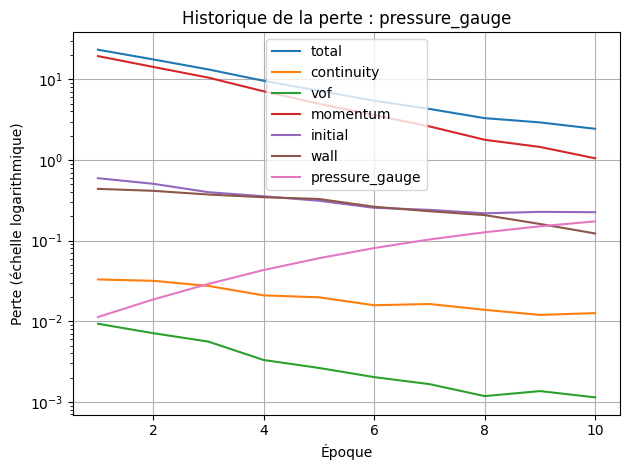

In [5]:
plot_history(ROOT / "models/sloshing_20261020_000522/history.json", use_same_figure=True)

In [ ]:
import torch
import numpy as np

field_names = ("u", "v", "p", "alpha")

times = np.asarray(data["time"], dtype=np.float32).reshape(-1)
n_times = len(times)

predictions = {
    name: np.empty((n_times, n_points), dtype=np.float32)
    for name in field_names
}

with torch.inference_mode():
    for i, time_value in enumerate(times):
        # X[i] contient les centres de cellules à cet instant.
        # Le modèle attend uniquement x, y, t.
        xy = X[i, :, :2]

        for start in range(0, n_points, batch_size):
            end = min(start + batch_size, n_points)
            coords_xy = xy[start:end]

            t_column = np.full(
                (end - start, 1),
                float(time_value),
                dtype=np.float32,
            )

            coords_np = np.concatenate(
                [coords_xy, t_column],
                axis=1,
            )

            coords = torch.as_tensor(
                coords_np,
                dtype=torch.float32,
                device=device,
            )

            pred = model.predict_physical(coords)

            for name in field_names:
                if name not in pred:
                    raise KeyError(
                        f"Le modèle ne renvoie pas le champ '{name}'."
                    )

                values = (
                    pred[name]
                    .detach()
                    .cpu()
                    .numpy()
                    .reshape(-1)
                )

                predictions[name][i, start:end] = values

        print(
            f"[SINN {i + 1}/{n_times}] "
            f"t = {time_value:.6g} s"
        )

In [ ]:
from visualization import animate_comparison

In [ ]:
animation, fig = animate_comparison(
    str(ROOT / "data" / "sloshing_data.npz"),
    model
    )